# MLFlow

Solution is written according to instructions in the `LAB_INSTRUCTION_2_MLFLOW.md` file.

## Dataset preparation

In [1]:
import numpy as np
import pandas as pd

from feature_engine.encoding import RareLabelEncoder
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

In [2]:
DATA_PATH = "data/ames_data_2006_2008.parquet"

df = pd.read_parquet(DATA_PATH)

# As we have temporal data, the best way to evaluate our model is time (chronological)
# split, where the newest data is used for testing. We will assume that we have the
# data for years 2006 and 2007, and evaluate using data from 2008.

df_train = df[df["YrSold"] < 2008]
df_test = df[df["YrSold"] == 2008]

y_train = df_train.pop("SalePrice")
y_test = df_test.pop("SalePrice")

categorical_features = df_train.select_dtypes(include="object").columns
numerical_features = df_train.select_dtypes(exclude="object").columns

print(f"Training samples: {df_train.shape[0]}")
print(f"Test samples: {df_test.shape[0]}")
print(f"Raw features: {df_train.shape[1]}")


Training samples: 1312
Test samples: 621
Raw features: 79


In [32]:
median_imputer = SimpleImputer(strategy="median")
min_max_scaler = MinMaxScaler()
rare_encoder = RareLabelEncoder(tol=0.01, n_categories=0, missing_values="ignore")
one_hot_encoder = OneHotEncoder(
    drop="first", sparse_output=False, handle_unknown="ignore"
)

num_pipeline = Pipeline(
    [("median_imputer", median_imputer), ("min_max_scaler", min_max_scaler)]
)

cat_pipeline = Pipeline(
    [("rare_encoder", rare_encoder), ("one_hot_encoder", one_hot_encoder)]
)

column_transformer = ColumnTransformer(
    [
        ("num_pipeline", num_pipeline, numerical_features),
        ("cat_pipeline", cat_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
)


<Axes: ylabel='Frequency'>

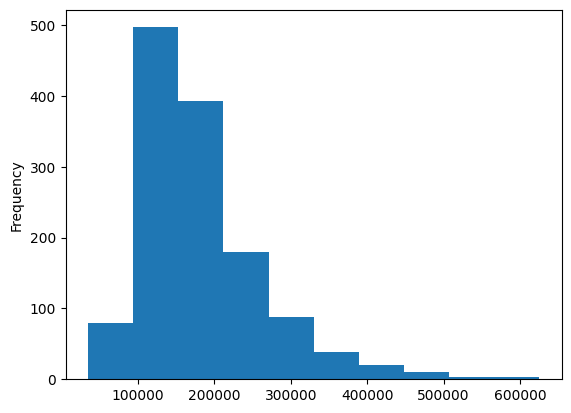

In [4]:
y_train.plot.hist()

<Axes: ylabel='Frequency'>

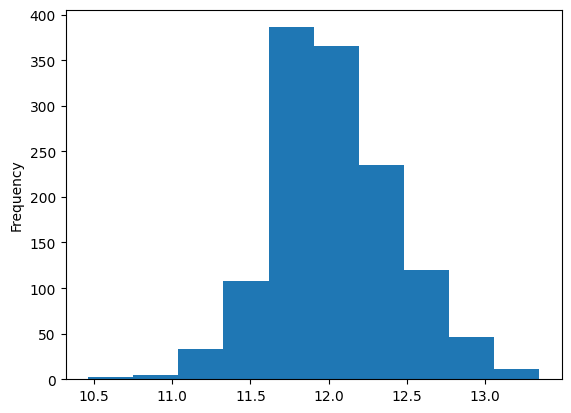

In [5]:
np.log1p(y_train).plot.hist()

## Training with autologging

In [6]:
import mlflow
import mlflow.sklearn

import warnings

warnings.filterwarnings("ignore")

mlflow.set_tracking_uri("http://localhost:5001")
print(f"Connected to MLflow at: {mlflow.get_tracking_uri()}")

Connected to MLflow at: http://localhost:5001


In [7]:
# log models with input examples, we will log datasets manually later
AUTOLOG_KWARGS = {"log_input_examples": True, "log_datasets": False, "silent": True}

mlflow.sklearn.autolog(**AUTOLOG_KWARGS)
mlflow.set_experiment("ames-housing-autolog")

2026/11/11 10:26:15 INFO mlflow.tracking.fluent: Experiment with name 'ames-housing-autolog' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1794389175905, experiment_id='1', last_update_time=1794389175905, lifecycle_stage='active', name='ames-housing-autolog', tags={}>

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor


models = [
    ("Ridge Regression", Ridge()),
    ("Decision Tree", DecisionTreeRegressor(max_depth=10, random_state=42)),
    ("K-Nearest Neighbors", KNeighborsRegressor(n_neighbors=10)),
    ("Random Forest", RandomForestRegressor(n_estimators=100, random_state=42)),
    ("Histogram Gradient Boosting", HistGradientBoostingRegressor(random_state=42)),
]


def make_pipeline(model) -> Pipeline:
    # train on log-prices, return predictions in dollars
    regressor = TransformedTargetRegressor(
        regressor=model, func=np.log1p, inverse_func=np.expm1
    )
    return Pipeline(
        [("preprocessing", clone(column_transformer)), ("model", regressor)]
    )

In [9]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


def cross_validate_without_autolog(pipeline: Pipeline, X, y) -> np.ndarray:
    mlflow.sklearn.autolog(disable=True)
    try:
        return cross_val_score(pipeline, X, y, cv=5, scoring="r2")
    finally:
        mlflow.sklearn.autolog(**AUTOLOG_KWARGS)


def fit_sklearn_models(models, df_train, df_test, y_train, y_test):
    results = {}

    for model_name, model in models:
        pipeline = make_pipeline(model)

        # start MLflow run - a unit grouping logs from different model runs
        # everything within this context manager will get logged as a run
        with mlflow.start_run(run_name=model_name):
            cv_scores = cross_validate_without_autolog(pipeline, df_train, y_train)

            pipeline.fit(df_train, y_train)
            y_pred = pipeline.predict(df_test)

            metrics = {
                "cv_r2_mean": cv_scores.mean(),
                "cv_r2_std": cv_scores.std(),
                "test_rmse": root_mean_squared_error(y_test, y_pred),
                "test_mae": mean_absolute_error(y_test, y_pred),
                "test_r2": r2_score(y_test, y_pred),
            }
            # log additional custom metrics, in addition to autologging
            mlflow.log_metrics(metrics)

            results[model_name] = metrics

            print(f"\n{model_name}:")
            print(f"  CV R^2 (mean ± std): {metrics['cv_r2_mean']:.3f} ± {metrics['cv_r2_std']:.3f}")
            print(f"  Test RMSE: {metrics['test_rmse']:.2f}")
            print(f"  Test MAE: {metrics['test_mae']:.2f}")
            print(f"  Test R^2: {metrics['test_r2']:.3f}")

    return results


In [10]:
sklearn_results = fit_sklearn_models(models, df_train, df_test, y_train, y_test)


Ridge Regression:
  CV R^2 (mean ± std): 0.912 ± 0.043
  Test RMSE: 20604.71
  Test MAE: 13581.70
  Test R^2: 0.926
🏃 View run Ridge Regression at: http://localhost:5001/#/experiments/1/runs/c37f1aac54f6401ba22132cb73295e41
🧪 View experiment at: http://localhost:5001/#/experiments/1

Decision Tree:
  CV R^2 (mean ± std): 0.731 ± 0.076
  Test RMSE: 37218.25
  Test MAE: 23082.59
  Test R^2: 0.758
🏃 View run Decision Tree at: http://localhost:5001/#/experiments/1/runs/27473e87259f4eaab6ecdb8ec143cc9e
🧪 View experiment at: http://localhost:5001/#/experiments/1

K-Nearest Neighbors:
  CV R^2 (mean ± std): 0.620 ± 0.026
  Test RMSE: 39498.84
  Test MAE: 26314.10
  Test R^2: 0.727
🏃 View run K-Nearest Neighbors at: http://localhost:5001/#/experiments/1/runs/85d6648c9f0847e9a70a70d26d602ea9
🧪 View experiment at: http://localhost:5001/#/experiments/1

Random Forest:
  CV R^2 (mean ± std): 0.861 ± 0.038
  Test RMSE: 25143.23
  Test MAE: 15518.41
  Test R^2: 0.889
🏃 View run Random Forest at: ht

## Data lineage

In [11]:
import yaml


def get_dvc_metadata(dvc_file_path):
    with open(dvc_file_path, "r") as f:
        dvc_data = yaml.safe_load(f)

    metadata = {
        "md5": dvc_data["outs"][0]["md5"],
        "size": dvc_data["outs"][0]["size"],
        "path": dvc_data["outs"][0]["path"],
    }
    return metadata


dvc_metadata = get_dvc_metadata(f"{DATA_PATH}.dvc")
print("DVC Metadata:")
print(f"MD5 hash: {dvc_metadata['md5']}")
print(f"File size: {dvc_metadata['size']} bytes")
print(f"Data path: {dvc_metadata['path']}")

DVC Metadata:
MD5 hash: f44053333f88a0646819936b37f000ee
File size: 162560 bytes
Data path: ames_data_2006_2008.parquet


In [12]:
import subprocess


def get_git_commit() -> str:
    result = subprocess.run(
        ["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True
    )
    return result.stdout.strip()


print(f"Git commit: {get_git_commit()}")

Git commit: 023be823f8ba9200db492978798561a9f252a3bc


In [22]:
# Extend fit_sklearn_models(), so that every run logs the dataset with mlflow.log_input() 
# Set the mlflow.source.git.commit tag to the current Git commit

def fit_sklearn_models(models, df_train, df_test, y_train, y_test):
    results = {}

    for model_name, model in models:
        pipeline = make_pipeline(model)

        with mlflow.start_run(run_name=model_name):

            dataset = mlflow.data.from_pandas(
                df_train,
                source=f"{DATA_PATH}.dvc",
                name="training_dataset"
            )
    
            mlflow.log_input(dataset, context="training") 
            mlflow.set_tag("mlflow.source.git.commit", get_git_commit())
            

            cv_scores = cross_validate_without_autolog(pipeline, df_train, y_train)

            pipeline.fit(df_train, y_train)
            y_pred = pipeline.predict(df_test)

            metrics = {
                "cv_r2_mean": cv_scores.mean(),
                "cv_r2_std": cv_scores.std(),
                "test_rmse": root_mean_squared_error(y_test, y_pred),
                "test_mae": mean_absolute_error(y_test, y_pred),
                "test_r2": r2_score(y_test, y_pred),
            }
            # log additional custom metrics, in addition to autologging
            mlflow.log_metrics(metrics)

            results[model_name] = metrics

            print(f"\n{model_name}:")
            print(f"  CV R^2 (mean ± std): {metrics['cv_r2_mean']:.3f} ± {metrics['cv_r2_std']:.3f}")
            print(f"  Test RMSE: {metrics['test_rmse']:.2f}")
            print(f"  Test MAE: {metrics['test_mae']:.2f}")
            print(f"  Test R^2: {metrics['test_r2']:.3f}")

    return results


In [23]:
models_new = [
    ("Decision Tree", DecisionTreeRegressor(max_depth=5, random_state=42)),
    ("K-Nearest Neighbors", KNeighborsRegressor(n_neighbors=5)),
    ("Random Forest", RandomForestRegressor(n_estimators=50, random_state=42)),
]

sklearn_results = fit_sklearn_models(models_new, df_train, df_test, y_train, y_test)


Decision Tree:
  CV R^2 (mean ± std): 0.720 ± 0.076
  Test RMSE: 38344.30
  Test MAE: 24678.22
  Test R^2: 0.743
🏃 View run Decision Tree at: http://localhost:5001/#/experiments/2/runs/33a95b93d47046f6a549f71b21710b76
🧪 View experiment at: http://localhost:5001/#/experiments/2

K-Nearest Neighbors:
  CV R^2 (mean ± std): 0.642 ± 0.041
  Test RMSE: 39660.28
  Test MAE: 26292.46
  Test R^2: 0.725
🏃 View run K-Nearest Neighbors at: http://localhost:5001/#/experiments/2/runs/df8abe5c07a748d6a9628a0ff9c2d276
🧪 View experiment at: http://localhost:5001/#/experiments/2

Random Forest:
  CV R^2 (mean ± std): 0.858 ± 0.038
  Test RMSE: 25564.87
  Test MAE: 15930.63
  Test R^2: 0.886
🏃 View run Random Forest at: http://localhost:5001/#/experiments/2/runs/d19fe356070242a7987ea52d5f1faa98
🧪 View experiment at: http://localhost:5001/#/experiments/2


In [26]:
# Create new version of the dataset

df_new = df[df["GrLivArea"] <= 3000].copy()

In [25]:
DATA_PATH_NEW = "data/ames_housing_filtered.csv"
df_new.to_csv(DATA_PATH_NEW, index=False)

In [27]:
df_new = pd.read_csv(DATA_PATH_NEW)

df_train = df_new[df_new["YrSold"] < 2008]
df_test = df_new[df_new["YrSold"] == 2008]

y_train = df_train.pop("SalePrice")
y_test = df_test.pop("SalePrice")

categorical_features = df_train.select_dtypes(include="object").columns
numerical_features = df_train.select_dtypes(exclude="object").columns

print(f"Training samples: {df_train.shape[0]}")
print(f"Test samples: {df_test.shape[0]}")
print(f"Raw features: {df_train.shape[1]}")


Training samples: 1300
Test samples: 618
Raw features: 79


In [33]:
models_new = [
    ("Decision Tree", DecisionTreeRegressor(max_depth=5, random_state=42)),
    ("K-Nearest Neighbors", KNeighborsRegressor(n_neighbors=5)),
]

sklearn_results = fit_sklearn_models(models_new, df_train, df_test, y_train, y_test)


Decision Tree:
  CV R^2 (mean ± std): 0.733 ± 0.075
  Test RMSE: 35260.57
  Test MAE: 23526.50
  Test R^2: 0.779
🏃 View run Decision Tree at: http://localhost:5001/#/experiments/2/runs/965c16662c844b078ca562fef60ad529
🧪 View experiment at: http://localhost:5001/#/experiments/2

K-Nearest Neighbors:
  CV R^2 (mean ± std): 0.689 ± 0.042
  Test RMSE: 37661.91
  Test MAE: 25542.99
  Test R^2: 0.748
🏃 View run K-Nearest Neighbors at: http://localhost:5001/#/experiments/2/runs/fb591e6e7e7641918436454857329633
🧪 View experiment at: http://localhost:5001/#/experiments/2


## Manual logging with PyTorch

In [36]:
import copy

import torch
import torch.nn as nn
from tabm import TabM
from torch.utils.data import DataLoader, TensorDataset

# disable sklearn autologging!
mlflow.sklearn.autolog(disable=True)

mlflow.set_experiment("pytorch-housing-manual")


2026/11/11 11:30:09 INFO mlflow.tracking.fluent: Experiment with name 'pytorch-housing-manual' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/3', creation_time=1794393009356, experiment_id='3', last_update_time=1794393009356, lifecycle_stage='active', name='pytorch-housing-manual', tags={}>

In [37]:
X_train = column_transformer.fit_transform(df_train)
X_test = column_transformer.transform(df_test)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, np.log1p(y_train), test_size=0.2, random_state=42
)

# standardization parameters are computed on training data only
y_log_mean, y_log_std = y_tr.mean(), y_tr.std()


def to_tensors(X: np.ndarray, y_log: pd.Series) -> tuple[torch.Tensor, torch.Tensor]:
    y_standardized = (y_log.to_numpy() - y_log_mean) / y_log_std
    return (
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y_standardized, dtype=torch.float32).reshape(-1, 1),
    )


train_data = to_tensors(X_tr, y_tr)
val_data = to_tensors(X_val, y_val)
test_data = to_tensors(X_test, np.log1p(y_test))

print(f"Train: {len(X_tr)}, validation: {len(X_val)}, test: {len(X_test)}")
print(f"Number of features: {X_train.shape[1]}")


Train: 1040, validation: 260, test: 618
Number of features: 182


In [38]:
class HousePriceNet(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 128, dropout_rate: float = 0.2):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x


In [39]:
def create_model(config: dict, n_features: int) -> nn.Module:
    if config["model"] == "mlp":
        return HousePriceNet(
            input_dim=n_features,
            hidden_dim=config["d_block"],
            dropout_rate=config["dropout"],
        )
    elif config["model"] == "tabm":
        return TabM.make(
            n_num_features=n_features,
            d_out=1,
            n_blocks=config["n_blocks"],
            d_block=config["d_block"],
            dropout=config["dropout"],
        )
    raise ValueError(f"Unknown model: {config['model']}")


In [40]:
class PyTorchTrainer:
    def __init__(self, config: dict):
        self.config = config

    @staticmethod
    def predict(model: nn.Module, X: torch.Tensor) -> torch.Tensor:
        # shape (batch, k): MLP has k=1, TabM has k submodels
        return model(X).reshape(len(X), -1)

    def train_epoch(
        self, model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer
    ) -> float:
        model.train()
        total_loss = 0.0

        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            y_pred = self.predict(model, X_batch)
            # mean of submodels' losses, not loss of the mean prediction
            loss = nn.functional.mse_loss(y_pred, y_batch.expand_as(y_pred))
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(X_batch)

        return total_loss / len(loader.dataset)

    @torch.no_grad()
    def evaluate(
        self, model: nn.Module, X: torch.Tensor, y: torch.Tensor
    ) -> dict[str, float]:
        model.eval()
        y_pred = self.predict(model, X).mean(dim=1, keepdim=True)

        # revert standardization and logarithm to compute errors in dollars
        y_pred_dollars = np.expm1(y_pred.numpy().ravel() * y_log_std + y_log_mean)
        y_true_dollars = np.expm1(y.numpy().ravel() * y_log_std + y_log_mean)

        return {
            "loss": nn.functional.mse_loss(y_pred, y).item(),
            "rmse": root_mean_squared_error(y_true_dollars, y_pred_dollars),
            "mae": mean_absolute_error(y_true_dollars, y_pred_dollars),
            "r2": r2_score(y_true_dollars, y_pred_dollars),
        }

    def fit(
        self,
        train_data: tuple[torch.Tensor, torch.Tensor],
        val_data: tuple[torch.Tensor, torch.Tensor],
    ) -> tuple[nn.Module, dict[str, float]]:
        torch.manual_seed(self.config["random_seed"])

        X_train, y_train = train_data
        model = create_model(self.config, n_features=X_train.shape[1])
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=self.config["learning_rate"],
            weight_decay=self.config["weight_decay"],
        )
        loader = DataLoader(
            TensorDataset(X_train, y_train),
            batch_size=self.config["batch_size"],
            shuffle=True,
        )

        best_metrics, best_state, best_epoch = None, None, 0
        for epoch in range(self.config["max_epochs"]):
            train_loss = self.train_epoch(model, loader, optimizer)
            val_metrics = self.evaluate(model, *val_data)

            # manually log metric values, with the epoch as the step
            mlflow.log_metrics(
                {
                    "train_loss": train_loss,
                    "val_loss": val_metrics["loss"],
                    "val_rmse": val_metrics["rmse"],
                },
                step=epoch,
            )

            if best_metrics is None or val_metrics["rmse"] < best_metrics["rmse"]:
                best_metrics, best_epoch = val_metrics, epoch
                best_state = copy.deepcopy(model.state_dict())
            elif epoch - best_epoch >= self.config["patience"]:
                break

        model.load_state_dict(best_state)
        mlflow.log_metric("best_epoch", best_epoch)
        mlflow.log_metrics({f"best_val_{name}": value for name, value in best_metrics.items()})

        return model, best_metrics


In [43]:
def train_and_log(config: dict) -> dict[str, float]:
    with mlflow.start_run(run_name=config["name"]):
        mlflow.log_params(config)

        trainer = PyTorchTrainer(config)
        model, val_metrics = trainer.fit(train_data, val_data)

        test_metrics = trainer.evaluate(model, *test_data)
        mlflow.log_metrics({f"test_{name}": value for name, value in test_metrics.items()})

        mlflow.pytorch.log_model(
            model, artifact_path=config["model"], input_example=val_data[0][:5].numpy()
        )

        print(
            f"{config['name']}: "
            f"validation RMSE {val_metrics['rmse']:.2f}, "
            f"test RMSE {test_metrics['rmse']:.2f}, "
            f"test R^2 {test_metrics['r2']:.3f}"
        )
        return test_metrics


In [44]:
base_config = {
    "random_seed": 42,
    "max_epochs": 200,
    "patience": 10,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "dropout": 0.1,
}

mlp_config = base_config | {"name": "mlp_baseline", "model": "mlp", "d_block": 128}
tabm_config = base_config | {
    "name": "tabm_default",
    "model": "tabm",
    "n_blocks": 3,
    "d_block": 128,
}

for config in [mlp_config, tabm_config]:
    train_and_log(config)


2026/11/11 11:32:51 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/11 11:33:00 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/11 11:33:00 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


mlp_baseline: validation RMSE 21166.30, test RMSE 22270.64, test R^2 0.912
🏃 View run mlp_baseline at: http://localhost:5001/#/experiments/3/runs/65ea0a562f1e42a782612801f77c65b5
🧪 View experiment at: http://localhost:5001/#/experiments/3


2026/11/11 11:33:56 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/11 11:34:04 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/11 11:34:04 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


tabm_default: validation RMSE 20247.43, test RMSE 21328.78, test R^2 0.919
🏃 View run tabm_default at: http://localhost:5001/#/experiments/3/runs/63901878c0144dd8ac62968c28c2eb84
🧪 View experiment at: http://localhost:5001/#/experiments/3


## Hyperparameter optimization with Optuna

In [47]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial: optuna.Trial) -> float:
    config = base_config | {
        "name": f"trial_{trial.number}",
        "model": "tabm",
        "n_blocks": 3,
        "d_block": 128,
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
    }

    with mlflow.start_run(run_name=config["name"], nested=True):
        mlflow.log_params(config)
        _, val_metrics = PyTorchTrainer(config).fit(train_data, val_data)

    return val_metrics["rmse"]


with mlflow.start_run(run_name="optuna_tabm"):
    study = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=42)
    )
    study.enqueue_trial(
        {"learning_rate": base_config["learning_rate"], "dropout": base_config["dropout"]}
    )
    study.optimize(objective, n_trials=5)

    mlflow.log_params(study.best_params)
    mlflow.log_metric("best_val_rmse", study.best_value)

print(f"Best validation RMSE: {study.best_value:.2f}")
print(f"Best hyperparameters: {study.best_params}")


🏃 View run trial_0 at: http://localhost:5001/#/experiments/3/runs/0b8cb65939b2475fb92b4e8af42d38ba
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_1 at: http://localhost:5001/#/experiments/3/runs/df7db6b3f9bf48918caff9f608064336
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_2 at: http://localhost:5001/#/experiments/3/runs/c8336e75ed364fdd9d7e02bdbd52799a
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_3 at: http://localhost:5001/#/experiments/3/runs/a33727a4f7a34911b358f676227cbaa2
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_4 at: http://localhost:5001/#/experiments/3/runs/1798e6499eb34680950484804eb271d4
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run optuna_tabm at: http://localhost:5001/#/experiments/3/runs/73e3b577a7ef4662bd814699c9ef854d
🧪 View experiment at: http://localhost:5001/#/experiments/3
Best validation RMSE: 20247.43
Best hyperp

In [48]:
best_tabm_config = base_config | {
    "name": "tabm_optuna_best",
    "model": "tabm",
    "n_blocks": 3,
    "d_block": 128,
    **study.best_params,
}
train_and_log(best_tabm_config)

2026/11/11 11:42:18 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/11 11:42:27 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/11 11:42:27 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


tabm_optuna_best: validation RMSE 20247.43, test RMSE 21328.78, test R^2 0.919
🏃 View run tabm_optuna_best at: http://localhost:5001/#/experiments/3/runs/86284545677b4be48375acb18192f7fa
🧪 View experiment at: http://localhost:5001/#/experiments/3


{'loss': 0.11635144799947739,
 'rmse': 21328.7804774784,
 'mae': 14178.237729280449,
 'r2': 0.9192679957464635}

In [50]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial: optuna.Trial) -> float:
    config = base_config | {
        "name": f"trial_{trial.number}",
        "model": "tabm",
        "n_blocks": trial.suggest_int("n_blocks", 1, 4),
        "d_block": trial.suggest_int("d_block", 64, 256, step=64),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128, 256])
    }

    with mlflow.start_run(run_name=config["name"], nested=True):
        mlflow.log_params(config)
        _, val_metrics = PyTorchTrainer(config).fit(train_data, val_data)

    return val_metrics["rmse"]


with mlflow.start_run(run_name="optuna_tabm"):
    study = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=42)
    )
    study.enqueue_trial(
        {"learning_rate": base_config["learning_rate"], "dropout": base_config["dropout"]}
    )
    study.optimize(objective, n_trials=20)

    mlflow.log_params(study.best_params)
    mlflow.log_metric("best_val_rmse", study.best_value)

print(f"Best validation RMSE: {study.best_value:.2f}")
print(f"Best hyperparameters: {study.best_params}")

🏃 View run trial_0 at: http://localhost:5001/#/experiments/3/runs/ee82566918424d2aaf11e202c23295af
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_1 at: http://localhost:5001/#/experiments/3/runs/c9e174b4cef546c7b91290aca6229668
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_2 at: http://localhost:5001/#/experiments/3/runs/13d2054f95c04f8e901ac88213b56508
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_3 at: http://localhost:5001/#/experiments/3/runs/50afee66107b4079b26df3f52368be6b
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_4 at: http://localhost:5001/#/experiments/3/runs/c9430fd4678d484fbd221046423e2fd0
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_5 at: http://localhost:5001/#/experiments/3/runs/4cf45eca54d94a30a8be4bf255de6e8f
🧪 View experiment at: http://localhost:5001/#/experiments/3
🏃 View run trial_6 at: http://localhost:5001/#

In [51]:
best_tabm_config = base_config | {
    "name": "tabm_optuna_best_new",
    "model": "tabm",
    **study.best_params,
}
train_and_log(best_tabm_config)

2026/11/11 12:27:04 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/11 12:27:11 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/11 12:27:11 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


tabm_optuna_best_new: validation RMSE 19536.30, test RMSE 21036.81, test R^2 0.921
🏃 View run tabm_optuna_best_new at: http://localhost:5001/#/experiments/3/runs/4d01e4d858d14b5690340881e89b7755
🧪 View experiment at: http://localhost:5001/#/experiments/3


{'loss': 0.11206453293561935,
 'rmse': 21036.80920623201,
 'mae': 13947.045585608068,
 'r2': 0.9214631602033083}

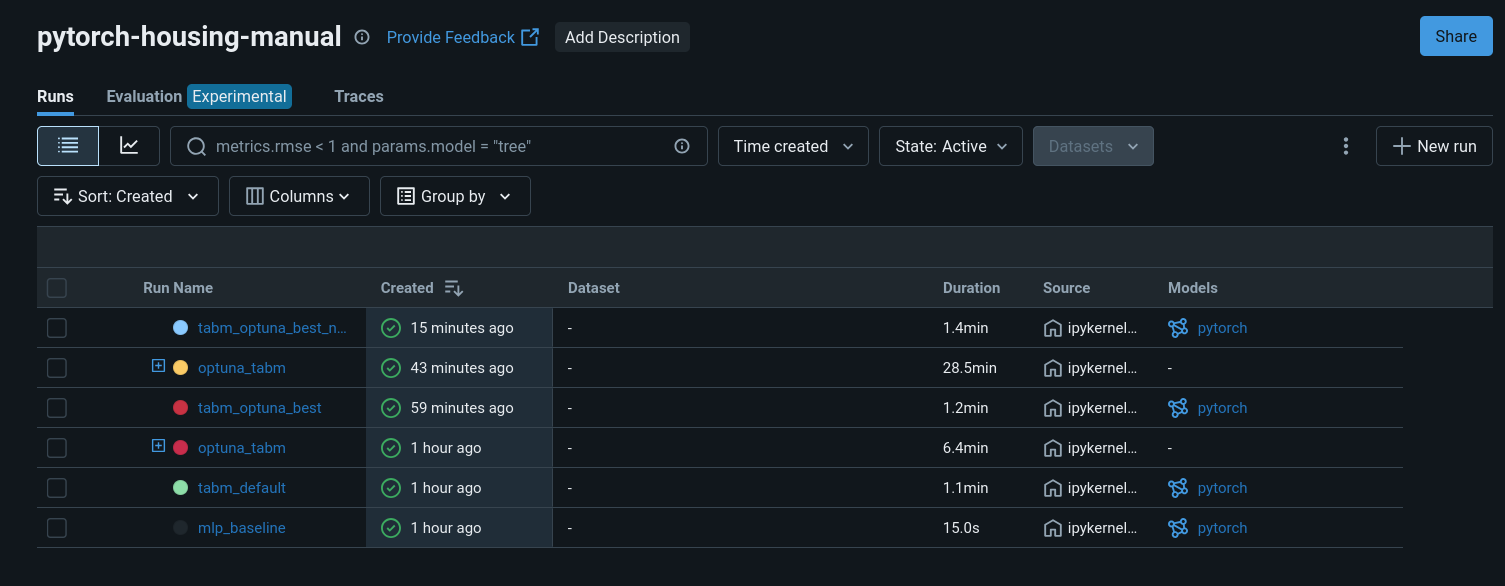

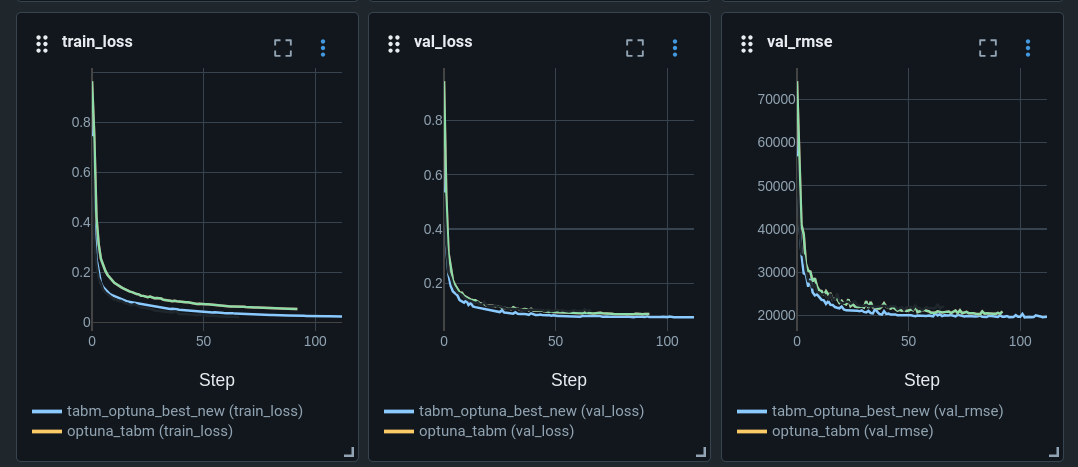

In overfitting avoidance following settings helped:
* higher dropout
* higher weight decay
* lower n_blocks


## Model registry

In [55]:
from mlflow import MlflowClient

MODEL_NAME = "ames-price"
client = MlflowClient()

runs = mlflow.search_runs(
    experiment_names=["ames-housing-autolog"],
    filter_string="metrics.cv_r2_mean > 0",
    order_by=["metrics.cv_r2_mean DESC"],
)
best_run = runs.iloc[0]
print(f"Best run: {best_run['tags.mlflow.runName']}, CV R^2: {best_run['metrics.cv_r2_mean']:.3f}")

model_uri = f"runs:/{best_run['run_id']}/model"
print(f"Logged model URI: {model_uri}")

model_version = mlflow.register_model(model_uri, MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "champion", model_version.version)
print(f"Registered {MODEL_NAME} version {model_version.version} as champion")


Successfully registered model 'ames-price'.
2026/11/11 12:33:22 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ames-price, version 1


Best run: Ridge Regression, CV R^2: 0.912
Logged model URI: runs:/c37f1aac54f6401ba22132cb73295e41/model
Registered ames-price version 1 as champion


Created version '1' of model 'ames-price'.


In [58]:
champion = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@champion")

predictions = champion.predict(df_test.dropna().head())
print(pd.DataFrame({"predicted": predictions.round(), "actual": y_test.head().to_numpy()}))


   predicted  actual
0   167767.0  176500
1   175633.0  237500
2   353698.0  206900
3   329296.0  187500
4   384002.0  165000


In [59]:
# Second best

MODEL_NAME = "ames-price-2"
client = MlflowClient()

best_run_2 = runs.iloc[1]
print(f"Best run: {best_run_2['tags.mlflow.runName']}, CV R^2: {best_run['metrics.cv_r2_mean']:.3f}")

model_uri_2 = f"runs:/{best_run_2['run_id']}/model"
print(f"Logged model URI: {model_uri_2}")

model_version_2 = mlflow.register_model(model_uri_2, MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "champion", model_version_2.version)
print(f"Registered {MODEL_NAME} version {model_version_2.version} as champion")


Successfully registered model 'ames-price-2'.
2026/11/11 12:35:45 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ames-price-2, version 1


Best run: Histogram Gradient Boosting, CV R^2: 0.912
Logged model URI: runs:/72b28be5182c457c99f89746e561554b/model
Registered ames-price-2 version 1 as champion


Created version '1' of model 'ames-price-2'.


In [60]:
champion_2 = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@champion")

predictions = champion_2.predict(df_test.dropna().head())
print(pd.DataFrame({"predicted": predictions.round(), "actual": y_test.head().to_numpy()}))

   predicted  actual
0   171985.0  176500
1   185242.0  237500
2   327142.0  206900
3   372203.0  187500
4   390773.0  165000


Loading models by alias is better than hardcoding versions, since instead of changing the version whenever a new model is deployed, only the model alias can be updated in the model registry. In this approach we don't have to modify the app. Aliases also improve code readability by providing interpretable names.